c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Đang sử dụng thiết bị: cpu

--- 1. CHẠY CẤU HÌNH BASELINE ---


100.0%
[I 2026-10-25 15:56:18,227] A new study created in memory with name: cnn_hpo_study


[Baseline] Validation Accuracy: 0.6232 | Runtime: 333.92s

--- 2. BẮT ĐẦU TỐI ƯU HÓA BẰNG OPTUNA ---


[I 2026-10-25 15:57:07,062] Trial 0 finished with value: 0.5995 and parameters: {'lr': 0.007117901632724973, 'batch_size': 64, 'optimizer': 'SGD', 'dropout_rate': 0.5431658286266227}. Best is trial 0 with value: 0.5995.
[I 2026-10-25 15:58:09,975] Trial 1 finished with value: 0.4701 and parameters: {'lr': 0.0003670683434691604, 'batch_size': 16, 'optimizer': 'SGD', 'dropout_rate': 0.4965808007606347}. Best is trial 0 with value: 0.5995.
[I 2026-10-25 15:58:58,518] Trial 2 finished with value: 0.1274 and parameters: {'lr': 2.4837192243905663e-05, 'batch_size': 64, 'optimizer': 'SGD', 'dropout_rate': 0.6657897539747081}. Best is trial 0 with value: 0.5995.
[I 2026-10-25 15:59:59,959] Trial 3 finished with value: 0.226 and parameters: {'lr': 2.1517009113677827e-05, 'batch_size': 16, 'optimizer': 'SGD', 'dropout_rate': 0.3134105273506013}. Best is trial 0 with value: 0.5995.
[I 2026-10-25 16:00:55,711] Trial 4 finished with value: 0.482 and parameters: {'lr': 9.026047172730744e-05, 'batch_


[Nghiệm Tốt Nhất - Best Trial]
Accuracy: 0.5995
Cấu hình: {'lr': 0.007117901632724973, 'batch_size': 64, 'optimizer': 'SGD', 'dropout_rate': 0.5431658286266227}

--- 3. XUẤT KẾT QUẢ ---
Đã lưu lịch sử chạy tại: results/optuna_trials_history.csv


C:\Users\DELL\AppData\Local\Temp\ipykernel_33284\3176660994.py:160: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  fig_importance = plot_param_importances(study)


Đã xuất biểu đồ hội tụ và tầm quan trọng tại thư mục figures/


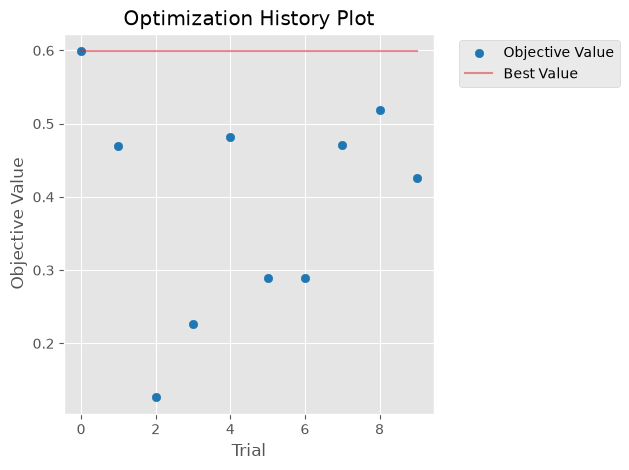

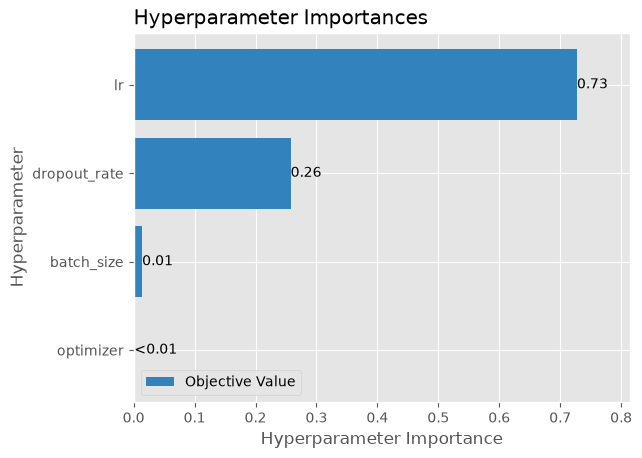

In [3]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import optuna
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

# 1. Tạo các thư mục lưu trữ theo chuẩn Portfolio
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# 2. Cố định Seed đảm bảo tính tái lập (Reproducibility)
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang sử dụng thiết bị: {device}")

# 3. Tải và Xử lý Dữ liệu CIFAR-10
def get_data_loaders(batch_size):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])
    trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
    
    # Chia 80% Train / 20% Validation (Không đụng vào Test set)
    train_size = int(0.8 * len(trainset))
    val_size = len(trainset) - train_size
    train_dataset, val_dataset = torch.utils.data.random_split(
        trainset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
    )
    
    trainloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    valloader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    return trainloader, valloader

# 4. Kiến trúc Mô hình CNN (Biến x: dropout_rate)
class SimpleCNN(nn.Module):
    def __init__(self, dropout_rate=0.5):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 32 * 8 * 8)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# 5. Hàm Huấn luyện & Đánh giá
def train_and_evaluate(model, trainloader, valloader, optimizer, criterion, epochs=3):
    model.to(device)
    best_val_acc = 0.0
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, labels in valloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                
        val_acc = correct / total
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            
    runtime = time.time() - start_time
    return best_val_acc, runtime

# 6. Khởi chạy Baseline làm mốc so sánh
print("\n--- 1. CHẠY CẤU HÌNH BASELINE ---")
set_seed(42)
trainloader_base, valloader_base = get_data_loaders(batch_size=32)
baseline_model = SimpleCNN(dropout_rate=0.5)
criterion = nn.CrossEntropyLoss()
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=1e-3)

baseline_acc, baseline_time = train_and_evaluate(
    baseline_model, trainloader_base, valloader_base, baseline_optimizer, criterion, epochs=3
)
print(f"[Baseline] Validation Accuracy: {baseline_acc:.4f} | Runtime: {baseline_time:.2f}s")

# 7. Tối ưu hóa siêu tham số (HPO) với Optuna
def objective(trial):
    # Ràng buộc miền tìm kiếm (Search Space)
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam", "RMSprop", "SGD"])
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.7)
    
    trainloader, valloader = get_data_loaders(batch_size=batch_size)
    model = SimpleCNN(dropout_rate=dropout_rate)
    
    if optimizer_name == "Adam":
        optimizer = optim.Adam(model.parameters(), lr=lr)
    elif optimizer_name == "RMSprop":
        optimizer = optim.RMSprop(model.parameters(), lr=lr)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
        
    # Hàm mục tiêu: Cực đại hóa Validation Accuracy
    val_acc, _ = train_and_evaluate(model, trainloader, valloader, optimizer, criterion, epochs=3)
    return val_acc

print("\n--- 2. BẮT ĐẦU TỐI ƯU HÓA BẰNG OPTUNA ---")
study = optuna.create_study(direction="maximize", study_name="cnn_hpo_study")
study.optimize(objective, n_trials=10)  # Chạy nháp 10 lần thử

print("\n[Nghiệm Tốt Nhất - Best Trial]")
print(f"Accuracy: {study.best_trial.value:.4f}")
print("Cấu hình:", study.best_trial.params)

# 8. Xuất dữ liệu Log và Biểu đồ chuẩn bị cho Báo cáo
df_results = study.trials_dataframe()
df_results.to_csv("results/optuna_trials_history.csv", index=False)
print("\n--- 3. XUẤT KẾT QUẢ ---")
print("Đã lưu lịch sử chạy tại: results/optuna_trials_history.csv")

fig_history = plot_optimization_history(study)
fig_history.figure.savefig("figures/optimization_history.png", bbox_inches='tight')

fig_importance = plot_param_importances(study)
fig_importance.figure.savefig("figures/param_importances.png", bbox_inches='tight')
print("Đã xuất biểu đồ hội tụ và tầm quan trọng tại thư mục figures/")

In [2]:
!pip install torch torchvision optuna pandas matplotlib scikit-learn

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 3.4 MB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 2.9 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 3.2 MB/s  0:00:00
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ------------ --------------------------- 0.8/2.4 MB 3.6 MB/s eta 0:00:01
   ------------------------------ --------- 1.8/2.4 MB 4.4 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 4.4 MB/s  0:00:00

   ---------------------------------------- 0/8 [tqdm]
   ----- ---------------------------------- 1/8 [sqlalchemy]
   ----- ---------------------------------- 1/8 [sqlalchemy]
   ----- ---------------------------------- 1/8 [sqlalchemy]
   ----- ---------------------------------- 1/8 [sqlalchemy]
   ----- ---------------------------------- 1/8 [sqlalchemy]
   ----- ---------------------------------- 1/8 [sq

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
